# 05. DBSCAN: k-distance dan pencarian parameter

DBSCAN dijalankan pada fitur aktivitas yang sama dengan K-Means. Kepadatan berada di ruang fitur, sehingga cluster tidak harus berdekatan secara geografis.

[Panduan](../00_panduan.ipynb) | [Sebelumnya](../04_kmeans/04_kmeans.ipynb) | [Berikutnya](../06_model_evaluation/06_model_evaluation.ipynb)

### Daftar bagian

- [1. Inisialisasi dan dependensi](#s1)
- [2. Metrik, noise, dan profiling](#s2)
- [3. k-distance, screening fragmentasi, dan model](#s3)
- [4. Jalankan DBSCAN](#s4)
- [5. Penamaan dan interpretasi kelompok (setelah clustering)](#s5)
- [6. Tabel nama kelompok dan angka dasarnya](#s6)
- [7. Periksa k-distance dan hasil cluster](#s7)

<a id="s1"></a>
## 1. Inisialisasi dan dependensi

Jalankan dari atas ke bawah dengan kernel Python 3.12.11 (Seismic Research). Konfigurasi tersentral di config.json.

In [1]:
from pathlib import Path
import os
import sys

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")
candidates = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    candidates.extend([parent, parent / "seismic_research_2021_2025"])
ROOT = next((p for p in candidates if (p / "config.json").is_file() and (p / "src/common.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Buka notebook dari folder proyek seismic_research_2021_2025.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display, Image, Markdown, FileLink
from src.common import read_config
cfg = read_config(ROOT)
print("Interpreter:", sys.executable)
print("Python:", sys.version.split()[0])
print("Proyek:", ROOT)
print("Training:", cfg["train_start"], "sampai sebelum", cfg["train_end_exclusive"])
print("Testing sampai sebelum (UTC):", cfg["test_end_exclusive"])

from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from threadpoolctl import threadpool_limits
from src.common import ROOT, load_prepared, save_model_metadata

Interpreter: C:\Users\yudhi\.local\bin\python3.12.exe
Python: 3.12.11
Proyek: C:\Users\yudhi\Documents\machine-learning\seismic_research_2021_2025
Training: 2021-01-01 sampai sebelum 2026-01-01
Testing sampai sebelum (UTC): 2026-10-26


<a id="s2"></a>
## 2. Metrik, noise, dan profiling

Noise tidak dimasukkan ke Silhouette/DBI; coverage/noise selalu dilaporkan. Untuk perbandingan adil, notebook 06 mengevaluasi kedua metode pada subset identik.

In [2]:
def cluster_metrics(X, labels, sample_size=2000, seed=42):
    X, labels = np.asarray(X), np.asarray(labels)
    assigned = labels >= 0
    values, counts = np.unique(labels[assigned], return_counts=True)
    result = {"n_rows": len(labels), "n_clusters": len(values), "n_assigned": int(assigned.sum()),
              "noise_fraction": float((~assigned).mean()),
              "largest_cluster_fraction_assigned": float(counts.max()/counts.sum()) if len(counts) else np.nan,
              "smallest_cluster_size": int(counts.min()) if len(counts) else 0,
              "silhouette": np.nan, "davies_bouldin": np.nan, "silhouette_n": 0}
    if len(values) < 2 or assigned.sum() <= len(values):
        return result
    xx, yy = X[assigned], labels[assigned]
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(xx), min(sample_size, len(xx)), replace=False)
    observed = len(np.unique(yy[indices]))
    if 1 < observed < len(indices):
        result["silhouette"] = float(silhouette_score(xx[indices], yy[indices]))
        result["silhouette_n"] = len(indices)
    result["davies_bouldin"] = float(davies_bouldin_score(xx, yy))
    return result

def full_labels(panel, train, labels, method):
    values = train[["row_id"]].copy()
    values["cluster"] = labels
    result = panel.loc[panel["split"].eq("train")].merge(values, on="row_id", how="left", validate="one_to_one")
    result["profile"] = result["state"]
    valid = result["cluster"].notna()
    result.loc[valid, "profile"] = result.loc[valid, "cluster"].astype(int).map(
        lambda n: "NOISE" if n < 0 else f"{method.upper()}_P{n}")
    return result

def profile_table(result, features):
    eligible = result.loc[result["cluster"].notna()]
    table = eligible.groupby("profile")[features + ["earthquake_count", "frequency_per_month", "depth_coverage"]].mean()
    table["n_grid_quarters"] = eligible.groupby("profile").size()
    table["low_support_fraction"] = eligible.groupby("profile")["low_support"].mean()
    return table.reset_index()

def save_cluster_plot(root, method, X, labels):
    projection = PCA(n_components=2, random_state=42).fit_transform(X)
    fig, ax = plt.subplots(figsize=(9, 6))
    for label in sorted(np.unique(labels)):
        mask = labels == label
        ax.scatter(projection[mask, 0], projection[mask, 1], s=7, alpha=.45,
                   label=("Noise" if label < 0 else f"Profil {label}") if len(np.unique(labels)) <= 20 else None)
    ax.set(xlabel="PC1", ylabel="PC2", title=f"{method.upper()}: proyeksi PCA fitur training (bukan koordinat)")
    if len(np.unique(labels)) <= 20:
        ax.legend()
    fig.tight_layout()
    fig.savefig(Path(root) / f"reports/figures/{method}_pca.png", dpi=160)
    plt.close(fig)

<a id="s3"></a>
## 3. k-distance, screening fragmentasi, dan model

Uji min_samples 5/10/20, eps dari kuantil jarak ke tetangga ke-k. Dalam query k-neighbor diri sendiri ikut dihitung. Screening eksploratif: 2..20 cluster, cluster terkecil >=20 observasi, noise <=50%, dominasi <=95%. Batas ini kebijakan interpretasi berdasarkan diagnosis training, bukan hukum seismologi. Pengaruh kebijakan diuji di notebook 08. Semua kandidat disimpan; jika tak ada yang lolos, hasil berstatus diagnostik.

In [3]:
def fit_dbscan(root=ROOT):
    root = Path(root)
    cfg, panel, train, X, _, meta = load_prepared(root)
    rows = []
    fig, ax = plt.subplots(figsize=(9, 5))
    with threadpool_limits(limits=2):
        for min_samples in cfg["dbscan_min_samples"]:
            if min_samples > len(X):
                continue
            # Query X secara eksplisit: tetangga diri berjarak nol ikut dihitung seperti min_samples DBSCAN.
            distances = NearestNeighbors(n_neighbors=min_samples, n_jobs=1).fit(X).kneighbors(X)[0][:, -1]
            ax.plot(np.sort(distances), label=f"min_samples={min_samples}")
            candidates = sorted(set(float(v) for v in np.quantile(distances, cfg["dbscan_distance_quantiles"]) if v > 0))
            if not candidates:
                candidates = [0.05, 0.1, 0.2]
            for eps in candidates:
                labels = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=1).fit_predict(X)
                metrics = cluster_metrics(X, labels, cfg["silhouette_sample_size"])
                repeat_scores = [cluster_metrics(X, labels, cfg["silhouette_sample_size"], seed)["silhouette"] for seed in cfg["silhouette_seeds"]]
                metrics["silhouette"] = float(np.nanmean(repeat_scores)) if np.isfinite(repeat_scores).any() else np.nan
                metrics["silhouette_std"] = float(np.nanstd(repeat_scores)) if np.isfinite(repeat_scores).any() else np.nan
                accepted = (metrics["n_clusters"] >= 2 and np.isfinite(metrics["silhouette"])
                            and metrics["n_clusters"] <= cfg["dbscan_max_clusters"]
                            and metrics["smallest_cluster_size"] >= cfg["dbscan_min_cluster_size"]
                            and metrics["noise_fraction"] <= cfg["dbscan_max_noise_fraction"]
                            and metrics["largest_cluster_fraction_assigned"] <= cfg["dbscan_max_largest_cluster_fraction"])
                rows.append({"eps": eps, "min_samples": min_samples, "accepted": accepted, **metrics})
        scores = pd.DataFrame(rows)
        if scores.empty:
            raise ValueError("Tidak ada kandidat DBSCAN.")
        pool = scores.loc[scores["accepted"]]
        diagnostic_only = pool.empty
        if diagnostic_only:
            pool = scores
        selected = pool.sort_values(["silhouette", "noise_fraction"], ascending=[False, True], na_position="last").iloc[0]
        model = DBSCAN(eps=float(selected["eps"]), min_samples=int(selected["min_samples"]), n_jobs=1).fit(X)
    result = full_labels(panel, train, model.labels_, "dbscan")
    directory = root / "models/dbscan"
    scores.to_csv(directory / "parameter_search.csv", index=False)
    result.to_csv(directory / "training_labels.csv", index=False)
    profile_table(result, cfg["features"]).to_csv(directory / "profiles.csv", index=False)
    joblib.dump(model, directory / "model.joblib")
    save_model_metadata(root, "dbscan", meta, {"eps": float(selected["eps"]), "min_samples": int(selected["min_samples"]),
                        "diagnostic_only": diagnostic_only, "fit_split": "train",
                        "selection": "rata-rata silhouette tertinggi di kandidat lolos batas noise, dominasi, fragmentasi dan dukungan; jika tidak ada, hanya diagnostik"})
    ax.set(title="k-distance training: dasar kandidat eps", xlabel="Observasi diurutkan", ylabel="Jarak ke tetangga ke-k")
    ax.legend()
    fig.tight_layout()
    fig.savefig(root / "reports/figures/dbscan_k_distance.png", dpi=160)
    plt.close(fig)
    save_cluster_plot(root, "dbscan", X, model.labels_)
    if diagnostic_only:
        print("Tidak ada kandidat DBSCAN lolos kriteria. Hasil disimpan untuk diagnosis, bukan model yang telah tervalidasi.")
    return scores, result

<a id="s4"></a>
## 4. Jalankan DBSCAN



In [4]:
search, labels = fit_dbscan(ROOT)
display(search)
display(pd.read_csv(ROOT / "models/dbscan/profiles.csv"))

,eps,min_samples,accepted,n_rows,n_clusters,n_assigned,noise_fraction,largest_cluster_fraction_assigned,smallest_cluster_size,silhouette,davies_bouldin,silhouette_n,silhouette_std
0,0.053797,5,False,13471,251,7184,0.466706,0.066398,4,0.604499,0.491608,2000,0.004476
1,0.160168,5,False,13471,146,9947,0.261599,0.160551,3,0.234433,1.137431,2000,0.005439
2,0.291550,5,False,13471,51,11915,0.115507,0.408393,3,-0.111894,1.609884,2000,0.010101
3,0.491201,5,False,13471,14,13062,0.030362,0.372990,4,-0.040325,1.583346,2000,0.004472
4,0.104398,10,False,13471,95,7345,0.454755,0.064942,5,0.497585,0.972798,2000,0.003606
5,0.224183,10,False,13471,68,10118,0.248905,0.170389,10,0.219609,1.663853,2000,0.008390
6,0.387934,10,False,13471,19,12072,0.103853,0.402999,11,-0.036735,2.254685,2000,0.009915
7,0.610008,10,False,13471,2,13129,0.025388,0.963516,479,-0.076942,4.654283,2000,0.004896
8,0.172769,20,False,13471,42,7654,0.431816,0.180820,12,0.366648,1.060357,2000,0.006164
9,0.303197,20,True,13471,14,10233,0.240368,0.473761,20,-0.038214,2.059509,2000,0.005523


,profile,log_frequency,avg_magnitude,max_magnitude,avg_depth,shallow_fraction,earthquake_count,frequency_per_month,depth_coverage,n_grid_quarters,low_support_fraction
0,DBSCAN_P0,0.287682,3.663313,3.663313,18.528786,1.000000,1.000000,0.333333,1.0,4860,1.000000
1,DBSCAN_P1,0.650957,3.925287,4.219390,144.342596,0.009532,2.908497,0.969499,1.0,459,0.843137
2,DBSCAN_P2,0.287682,3.876994,3.876994,208.787572,0.000000,1.000000,0.333333,1.0,1730,1.000000
3,DBSCAN_P3,0.759680,3.610482,4.058462,23.415076,0.958257,3.703614,1.234538,1.0,4538,0.758484
4,DBSCAN_P4,0.510826,3.691542,3.983940,74.990685,0.500000,2.000000,0.666667,1.0,467,1.000000
5,DBSCAN_P5,0.742004,3.633752,4.113450,95.027495,0.307700,3.321637,1.107212,1.0,171,0.964912
6,DBSCAN_P6,0.510826,4.173214,4.314286,285.082143,0.000000,2.000000,0.666667,1.0,28,1.000000
7,NOISE,1.062988,3.965757,4.707471,165.102947,0.366171,8.091954,2.697318,1.0,1218,0.478654


<a id="s5"></a>
## 5. Penamaan dan interpretasi kelompok (setelah clustering)

DBSCAN sudah membentuk kelompok pada bagian sebelumnya. Di sini kita membaca cirinya lalu memberi nama deskriptif. Nama tidak menentukan anggota kelompok atau mengubah noise. Aturan nama sama dengan K-Means, tetapi Kelompok A DBSCAN tidak sama dengan Kelompok A K-Means. Statistik pembentuk nama hanya memakai training 2021-2025; tidak memakai testing 2026.

In [5]:
from src.mapping import profile_color

def profile_descriptions(root, method, cfg):
    profiles = pd.read_csv(Path(root) / f"models/{method}/profiles.csv")
    clusters = profiles.loc[profiles["profile"].str.contains("_P", regex=False)].copy()
    maximum_count = clusters["earthquake_count"].max()
    descriptions = {}
    for row in clusters.itertuples():
        number = int(row.profile.rsplit("_P", 1)[1])
        group = f"Kelompok {chr(65 + number)}"
        magnitude = f"{row.avg_magnitude:.1f}".replace(".", ",")
        count = f"{row.earthquake_count:.1f}".replace(".", ",")
        depth = f"{row.avg_depth:.0f}"
        if row.avg_depth < cfg["shallow_depth_km"]:
            characteristic = f"Cenderung dangkal, magnitudo sekitar {magnitude}"
        else:
            characteristic = f"Kedalaman sekitar {depth} km, magnitudo {magnitude}"
        if row.earthquake_count == maximum_count:
            characteristic = "Kejadian lebih sering; " + ("cenderung dangkal" if row.avg_depth < cfg["shallow_depth_km"] else f"kedalaman sekitar {depth} km")
        descriptions[row.profile] = {
            "name": group + ": " + characteristic,
            "detail": f"Rata-rata {count} kejadian / 3 bulan; magnitudo {magnitude}; kedalaman {depth} km.",
            "source": "Ringkasan statistik cluster historis 2021-2025, bukan kategori yang menentukan anggota cluster.",
            "color": profile_color(row.profile),
        }
    special_names = {
        "NO_EVENTS": f"Tidak ada gempa tercatat dengan magnitudo minimal {cfg['min_magnitude']:g}",
        "INCOMPLETE_FEATURES": "Data belum cukup untuk menentukan kelompok",
        "NOISE": "Tidak masuk kelompok historis DBSCAN",
        "NO_CORE_MATCH": "Belum cocok dengan kelompok historis",
        "AMBIGUOUS_CORE_MATCH": "Cocok dengan lebih dari satu kelompok",
    }
    for code, name in special_names.items():
        descriptions[code] = {"name": name, "detail": "Status data atau pencocokan model; bukan tingkat bahaya.",
                              "source": "Status pipeline", "color": profile_color(code)}
    return descriptions

def profile_interpretation_table(root, method, cfg):
    profiles = pd.read_csv(Path(root) / f"models/{method}/profiles.csv")
    descriptions = profile_descriptions(root, method, cfg)
    profiles["nama_kelompok"] = profiles["profile"].map(lambda code: descriptions[code]["name"])
    table = profiles[["profile", "nama_kelompok", "earthquake_count", "avg_magnitude", "avg_depth", "n_grid_quarters"]].copy()
    return table.rename(columns={
        "profile": "Kode algoritma", "nama_kelompok": "Nama untuk menjelaskan hasil",
        "earthquake_count": "Gempa per kotak per triwulan (rata-rata)",
        "avg_magnitude": "Magnitudo (rata-rata)", "avg_depth": "Kedalaman km (rata-rata)",
        "n_grid_quarters": "Jumlah kotak-periode pembentuk kelompok",
    }).round(2)

<a id="s6"></a>
## 6. Tabel nama kelompok dan angka dasarnya

Nama kelompok, jumlah kejadian, magnitudo, dan kedalaman ditampilkan berdampingan agar interpretasinya dapat diperiksa. Baris tidak masuk kelompok tetap dipisahkan sebagai status DBSCAN.

In [6]:
interpretation = profile_interpretation_table(ROOT, "dbscan", cfg)
with pd.option_context("display.max_colwidth", None):
    display(interpretation)
interpretation.to_csv(ROOT / "reports/evaluation/dbscan_profile_interpretation.csv", index=False)
print("Nama hanya menjelaskan hasil; keanggotaan dan status DBSCAN tidak diubah.")

,Kode algoritma,Nama untuk menjelaskan hasil,Gempa per kotak per triwulan (rata-rata),Magnitudo (rata-rata),Kedalaman km (rata-rata),Jumlah kotak-periode pembentuk kelompok
0,DBSCAN_P0,"Kelompok A: Cenderung dangkal, magnitudo sekitar 3,7",1.00,3.66,18.53,4860
1,DBSCAN_P1,"Kelompok B: Kedalaman sekitar 144 km, magnitudo 3,9",2.91,3.93,144.34,459
2,DBSCAN_P2,"Kelompok C: Kedalaman sekitar 209 km, magnitudo 3,9",1.00,3.88,208.79,1730
3,DBSCAN_P3,Kelompok D: Kejadian lebih sering; cenderung dangkal,3.70,3.61,23.42,4538
4,DBSCAN_P4,"Kelompok E: Kedalaman sekitar 75 km, magnitudo 3,7",2.00,3.69,74.99,467
5,DBSCAN_P5,"Kelompok F: Kedalaman sekitar 95 km, magnitudo 3,6",3.32,3.63,95.03,171
6,DBSCAN_P6,"Kelompok G: Kedalaman sekitar 285 km, magnitudo 4,2",2.00,4.17,285.08,28
7,NOISE,Tidak masuk kelompok historis DBSCAN,8.09,3.97,165.10,1218


Nama hanya menjelaskan hasil; keanggotaan dan status DBSCAN tidak diubah.


<a id="s7"></a>
## 7. Periksa k-distance dan hasil cluster

Skor tinggi dari ratusan cluster kecil tidak otomatis menjadi model paling berguna. Noise menggambarkan ketidakcocokan terhadap struktur kepadatan model, bukan risiko gempa.

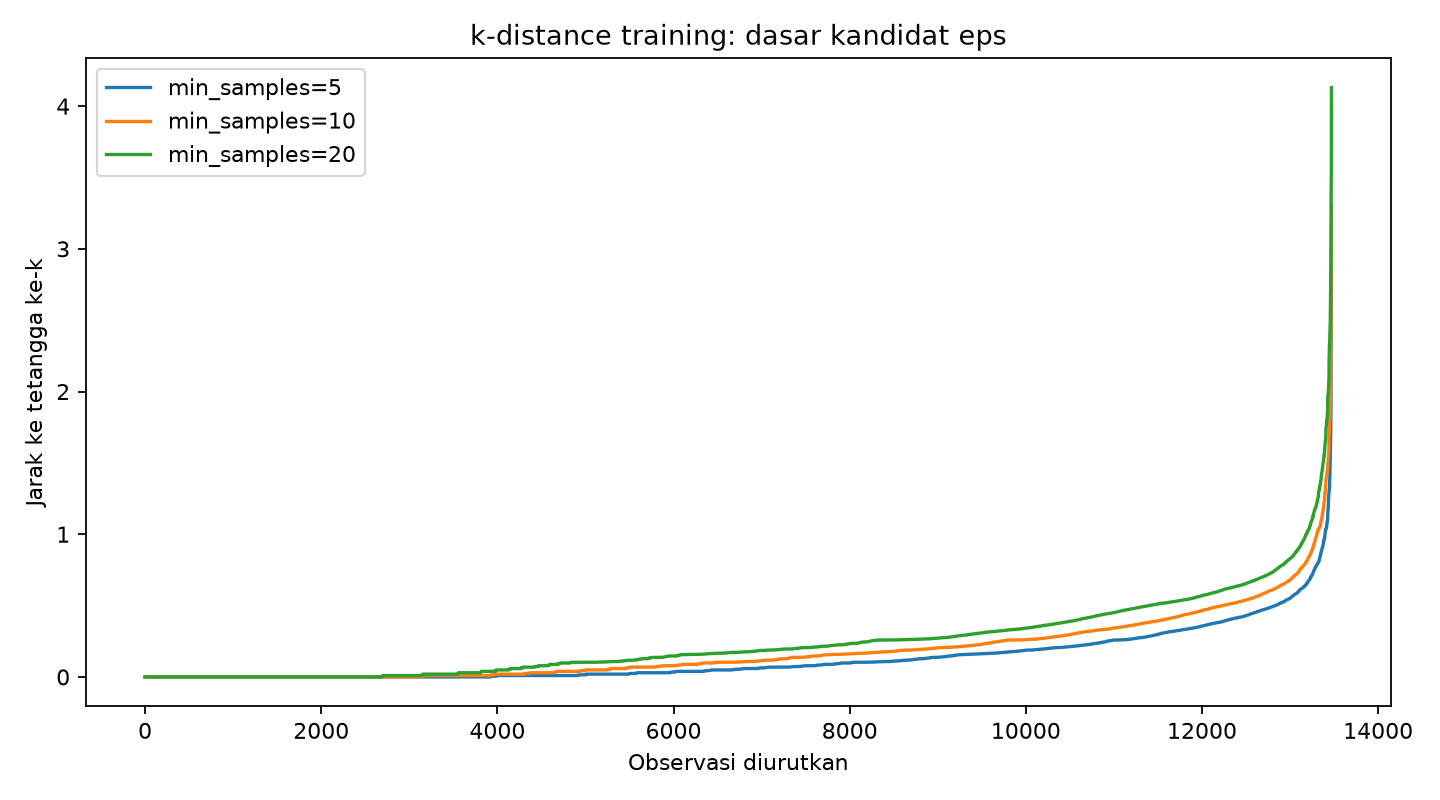

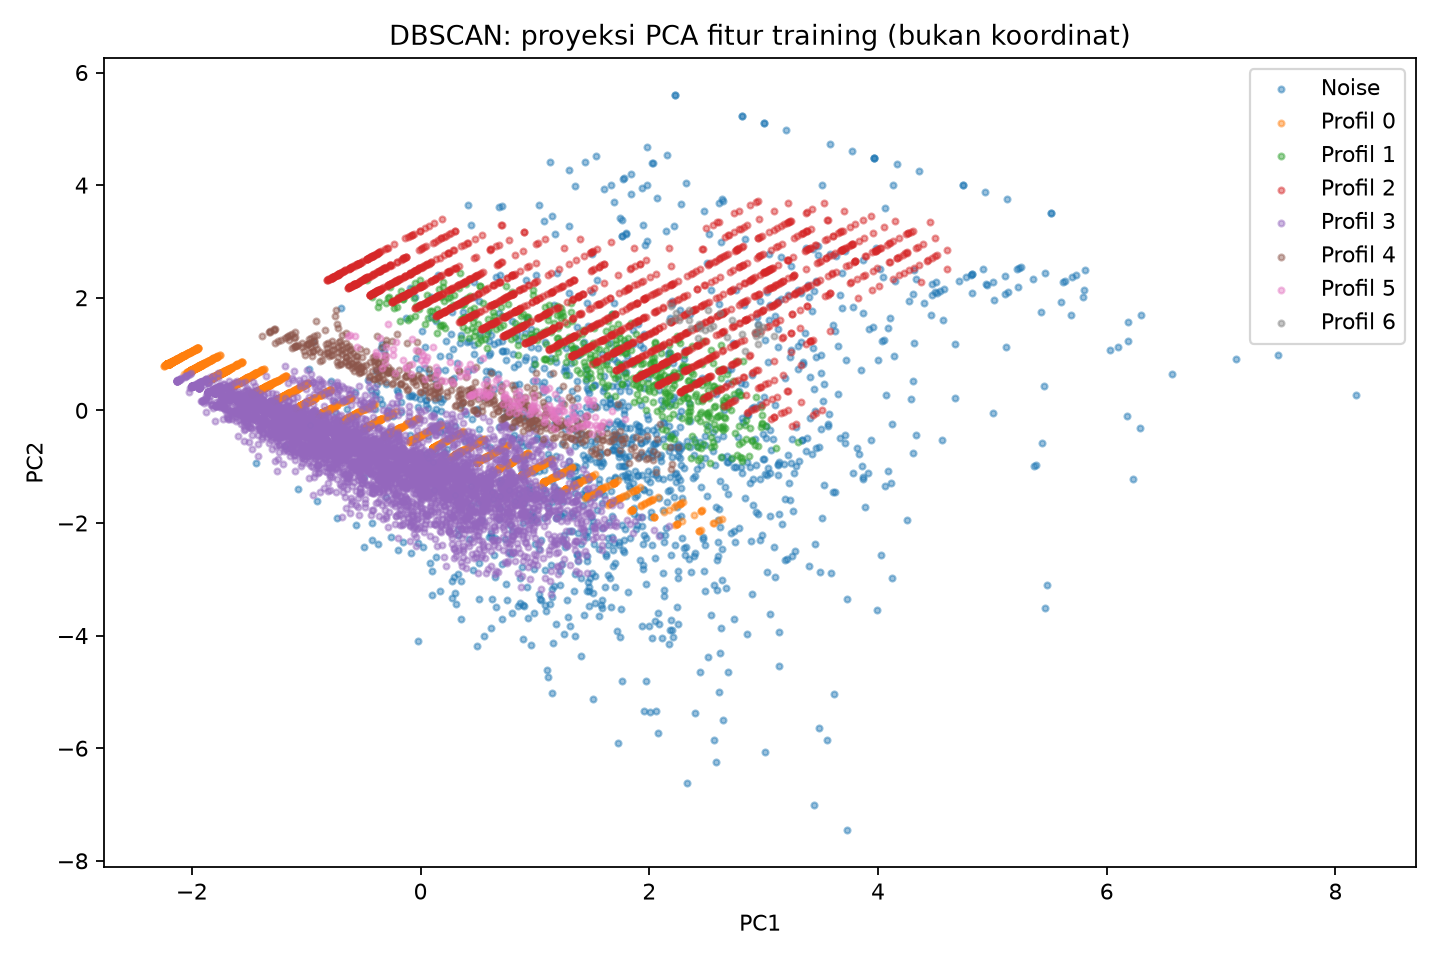

profile
NO_EVENTS    21689
DBSCAN_P0     4860
DBSCAN_P3     4538
DBSCAN_P2     1730
NOISE         1218
DBSCAN_P4      467
DBSCAN_P1      459
DBSCAN_P5      171
DBSCAN_P6       28
Name: n_grid_quarters, dtype: int64

In [7]:
display(Image(filename=str(ROOT / "reports/figures/dbscan_k_distance.png")))
display(Image(filename=str(ROOT / "reports/figures/dbscan_pca.png")))
display(labels["profile"].value_counts().rename("n_grid_quarters"))

## Referensi dan batas interpretasi

[Dokumentasi EMSC](https://www.seismicportal.eu/fdsn-wsevent.html), [clustering scikit-learn](https://scikit-learn.org/stable/modules/clustering.html), dan docs/metodologi.md. Hasil adalah profil aktivitas katalog dalam bounding box dan periode yang dipilih. Interpretasi risiko, prediksi kejadian gempa, serta klaim perubahan fisik memerlukan bukti tambahan.